# 05 · Grad-CAM y aprendizaje por atajos

Un modelo puede acertar por la razón equivocada. Construimos un atajo a propósito: en train, todas
las imágenes de la clase 1 tienen una «marca de agua» en una esquina (como el celular que tomó casi
todas las m1 en el dataset de cacao). Grad-CAM muestra dónde mira la red.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from common import set_seed, setup_style

setup_style()
rng = set_seed(42)
import torch
from torch import nn


class SmallCNN(nn.Module):
    def __init__(self, n_classes):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(),
        )
        self.pool = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten())
        self.head = nn.Linear(64, n_classes)

    def forward(self, x):
        return self.head(self.pool(self.features(x)))


def train(model, X, y, epochs=8, lr=1e-3, params=None):
    opt = torch.optim.Adam(params if params is not None else model.parameters(), lr=lr)
    gen = torch.Generator().manual_seed(42)
    for _ in range(epochs):
        model.train()
        for idx in torch.randperm(len(X), generator=gen).split(64):
            opt.zero_grad()
            nn.functional.cross_entropy(model(X[idx]), y[idx]).backward()
            opt.step()
    return model


@torch.no_grad()
def accuracy(model, X, y):
    model.eval()
    return (model(X).argmax(1) == y).float().mean().item()


from applied_cv.gradcam import grad_cam


def bars(n, watermark, size=32):
    X, y = np.zeros((n, 1, size, size), np.float32), rng.integers(0, 2, n)
    for i in range(n):
        r, c, L = rng.integers(8, 24), rng.integers(8, 24), rng.integers(6, 12)
        if y[i]:
            X[i, 0, r - L // 2 : r + L // 2, c] = 1.0  # barra vertical
        else:
            X[i, 0, r, c - L // 2 : c + L // 2] = 1.0  # barra horizontal
        if (watermark == "correlated" and y[i]) or (watermark == "random" and rng.random() < 0.5):
            X[i, 0, 1:4, 1:4] = 1.0
    X += rng.normal(0, 0.35, X.shape).astype(np.float32)
    return torch.tensor(X), torch.tensor(y)


torch.manual_seed(42)
Xtr, ytr = bars(2000, "correlated")
X_same, y_same = bars(500, "correlated")
X_none, y_none = bars(500, "none")
shortcut = train(SmallCNN(2), Xtr, ytr, epochs=6)
print(f"test con la marca: {accuracy(shortcut, X_same, y_same):.2f}")
print(f"test sin la marca: {accuracy(shortcut, X_none, y_none):.2f}")

test con la marca: 1.00
test sin la marca: 0.60


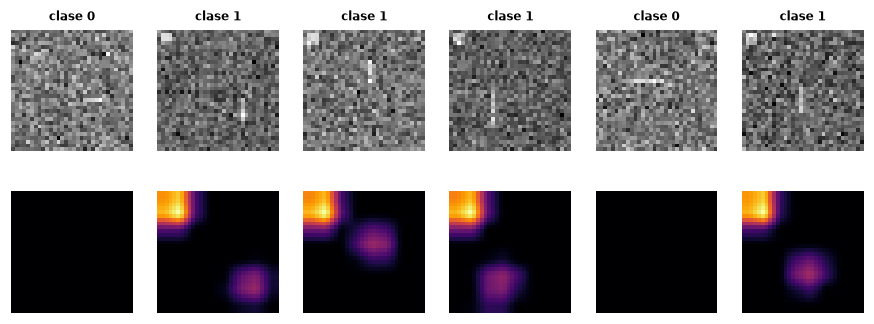

In [2]:
cams = grad_cam(shortcut, shortcut.features[-2], X_same[:6], target=1)
fig, ax = plt.subplots(2, 6, figsize=(10, 3.5))
for j in range(6):
    ax[0, j].imshow(X_same[j, 0], cmap="gray")
    ax[0, j].set_title(f"clase {int(y_same[j])}", fontsize=8)
    ax[1, j].imshow(cams[j], cmap="inferno")
    for a in ax[:, j]:
        a.axis("off")

In [3]:
Xr, yr = bars(2000, "random")
honest = train(SmallCNN(2), Xr, yr, epochs=6)
print(f"modelo sin atajo — test sin la marca: {accuracy(honest, X_none, y_none):.2f}")

modelo sin atajo — test sin la marca: 0.97


**Lectura.** Con la marca correlacionada con la clase, la red la usa (es más fácil que la
barra) y su exactitud se desploma cuando la marca desaparece; Grad-CAM se enciende en la esquina.
Si la marca aparece al azar en ambas clases, deja de ser útil y la red aprende la barra. En el cacao no
podemos borrar el celular de las fotos: por eso el proyecto mide el atajo (H3) y evalúa h0 vs. m1
dentro de un solo celular.